In [92]:
import numpy as np
import matplotlib.pyplot as plt
import math

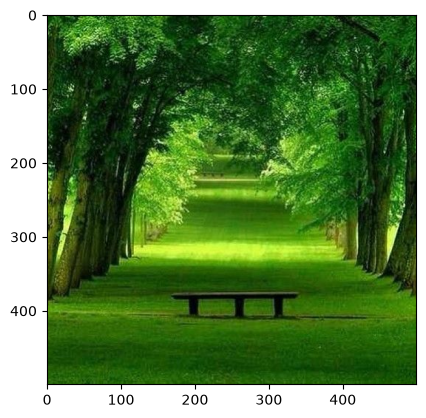

In [ ]:
img = plt.imread("src/pic.jpg")
plt.imshow(img)
def apply_ker(ker, size, mode, img):
    s = size//2
    if mode == "constant":
        for_res = np.pad(
            img,
            pad_width=((s, s), (s, s), (0, 0)),
            mode="constant",
            constant_values=0
        )
    elif mode == "reflect":
        for_res = np.pad(
            img,
            pad_width=((s, s), (s, s), (0, 0)),
            mode="reflect"
        )
    else:
        raise Exception("Invalid type of mode in apply_ker function")
    res = np.zeros((500, 500, 3))
    for i in range(0+s, img.shape[0]+s):
        for j in range(0+s, img.shape[1]+s):
            res[i-s, j-s] = (for_res[i-s:i+s+1, j-s:j+s+1] * ker[..., None]).sum(axis=(0, 1))
    res = np.clip(res, 0, 255)
    return res.astype(np.uint8)

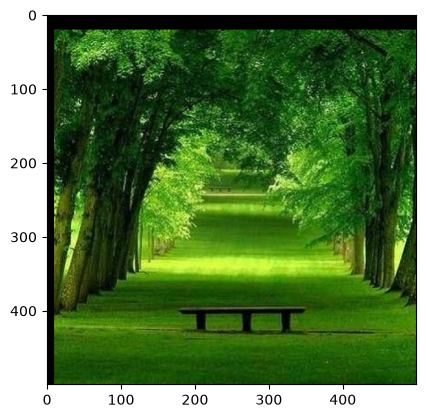

In [59]:
def shift(img):
    ker = np.zeros((41, 41), dtype=np.float32)
    ker[0][10] = 1
    return apply_ker(ker, 41, "constant", img)
plt.imshow(shift(img))

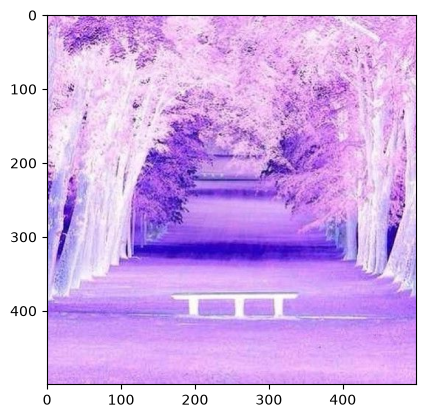

In [65]:
def inverse(img):
    ker = np.array([
        [0, 0, 0],
        [0, -1, 0],
        [0, 0, 0],
    ])
    for_res = np.pad(
        img,
        pad_width=((1, 1), (1, 1), (0, 0)),
        mode="constant",
        constant_values=0
    )
    res = np.zeros((500, 500, 3))
    for i in range(0+1, img.shape[0]+1):
        for j in range(0+1, img.shape[1]+1):
            res[i-1, j-1] = (for_res[i-1:i+1+1, j-1:j+1+1] * ker[..., None]).sum(axis=(0, 1)) + 255
    res = np.clip(res, 0, 255)
    return res.astype(np.uint8)
plt.imshow(inverse(img))

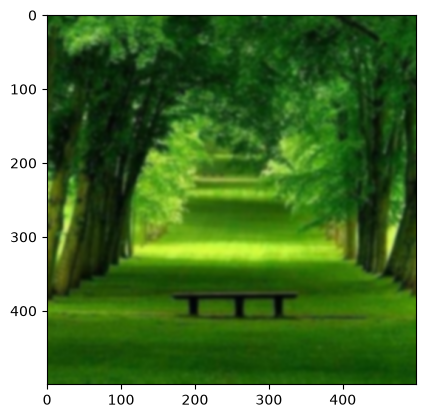

In [127]:
def gaussian(img, size, sigma):
    s = size // 2
    x, y = np.meshgrid(np.arange(-s, s+1), np.arange(-s, s+1))
    ker = 1/(2 * np.pi * sigma ** 2) * np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2))
    ker /= ker.sum()
    return apply_ker(ker, size, "reflect", img)
plt.imshow(gaussian(img, 11, 2))

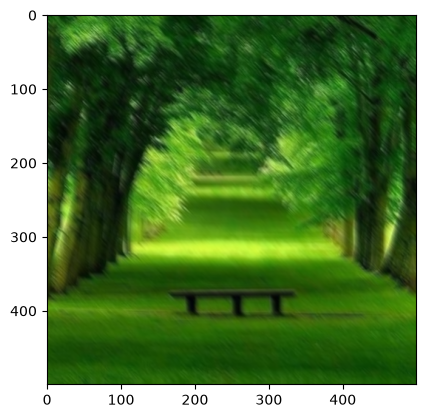

In [102]:
def inmove(img, size):
    s = size // 2
    ker = np.diag(np.arange(0, s * 2 + 1)).astype(np.float32)
    ker /= ker.sum()
    return apply_ker(ker, size, "reflect", img)
plt.imshow(inmove(img, 11))

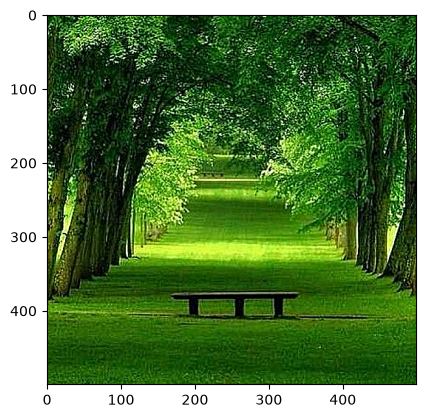

In [126]:
def sharpness(img, size, sigma, alpha):
    s = size // 2
    x, y = np.meshgrid(np.arange(-s, s+1), np.arange(-s, s+1))
    ker = 1/(2 * np.pi * sigma ** 2) * np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2))
    ker /= ker.sum()
    I = np.zeros((size+(not size%2), size+(not size%2)))
    I[s, s] = 1
    ker = (1 + alpha) * I - alpha * ker
    return apply_ker(ker, size, "reflect", img)
plt.imshow(sharpness(img, 5, 10, 2)) 

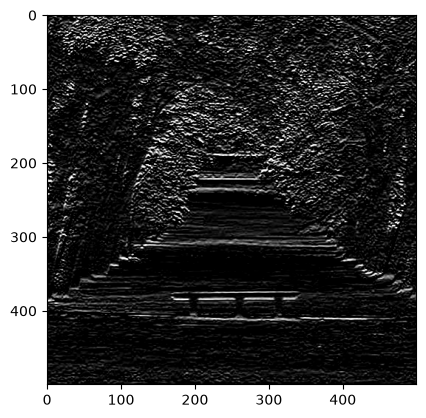

In [117]:
def sobel(img, size):
    s = size // 2
    ker = np.arange(-s, s+1)
    for_ker = np.array([math.comb(size - 1, i) for i in range(size)])
    ker = np.outer(ker, for_ker)
    return apply_ker(ker, size, "reflect", img[..., 1][..., None])
plt.imshow(sobel(img, 3), cmap="gray")

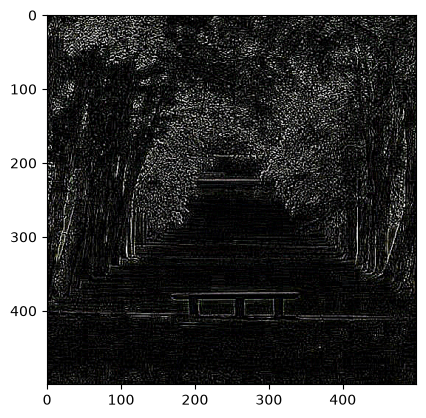

In [124]:
def border(img, size):
    s = size // 2
    ker = np.full((s * 2 + 1, s * 2 + 1), -1)
    ker[s, s] = -ker.sum() - 1
    return apply_ker(ker, size, "reflect", img)
plt.imshow(border(img, 3))

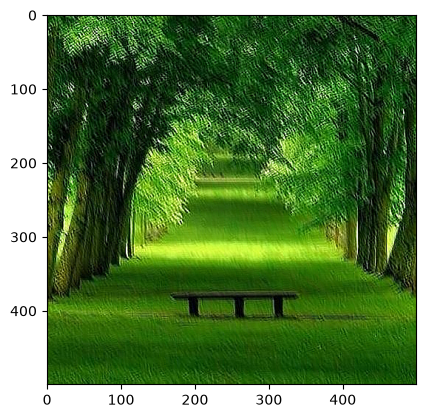

In [149]:
def mine(img):
    ker = np.array([
        [1, 1, -1],
        [-1, 1, -1],
        [-1, 1, 1]
    ])
    return apply_ker(ker, 3, "reflect", img)
plt.imshow(mine(img))